In [1]:
# ============================================================
# VISIONPORT EXPERIMENT 2
# END-TO-END DEEP LEARNING SYSTEM ARCHITECTURE
# FastAPI + Triton + TensorRT + YOLO + GPU
# CELL 1: INSTALL DEPENDENCIES
# ============================================================
!pip install -q -U ultralytics fastapi uvicorn python-multipart requests

In [2]:
# CELL 2: IMPORT LIBRARIES
import os
import time
import threading
import requests
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import uvicorn

from io import BytesIO
from PIL import Image
from ultralytics import YOLO
from fastapi import FastAPI, UploadFile, File
from google.colab import files

# Port used by our FastAPI server (8000 is reserved for Triton's default HTTP port)
API_PORT = 8080
API_URL = f"http://127.0.0.1:{API_PORT}"

print("=" * 65)
print("       VISIONPORT - END-TO-END SYSTEM ARCHITECTURE")
print("=" * 65)

       VISIONPORT - END-TO-END SYSTEM ARCHITECTURE


In [3]:
# CELL 3: CHECK HARDWARE AND SOFTWARE
gpu_available = torch.cuda.is_available()
hardware = torch.cuda.get_device_name(0) if gpu_available else "CPU"

print("SYSTEM CONFIGURATION")
print("-" * 45)
print("PyTorch Version:", torch.__version__)
print("GPU Available:", gpu_available)
print("Hardware:", hardware)

# TensorRT
try:
    import tensorrt as trt
    tensorrt_available = True
    trt_version = trt.__version__
except Exception:
    tensorrt_available = False
    trt_version = "Not installed"

# Triton client
try:
    import tritonclient
    triton_client_available = True
except Exception:
    triton_client_available = False

# Triton server health endpoint (default port 8000)
try:
    triton_running = requests.get(
        "http://localhost:8000/v2/health/ready", timeout=2
    ).status_code == 200
except Exception:
    triton_running = False

print("TensorRT:", trt_version)
print("Triton Client Installed:", triton_client_available)
print("Triton Server Running:", triton_running)

SYSTEM CONFIGURATION
---------------------------------------------
PyTorch Version: 2.14.1+cpu
GPU Available: False
Hardware: CPU
TensorRT: Not installed
Triton Client Installed: False
Triton Server Running: False


In [4]:
# CELL 3: UPLOAD A REAL IMAGE
import requests

url = "https://ultralytics.com/images/bus.jpg"
# other option: "https://ultralytics.com/images/zidane.jpg"
image_path = "input.jpg"

r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
r.raise_for_status()
with open(image_path, "wb") as f:
    f.write(r.content)
print("Saved:", image_path)

Saved: input.jpg


In [5]:
# CELL 5: LOAD YOLO MODEL
print("Loading YOLOv8 Model...")
model = YOLO("yolov8n.pt")
print("YOLOv8 Model Loaded Successfully!")

Loading YOLOv8 Model...
YOLOv8 Model Loaded Successfully!


In [6]:
# CELL 6: CREATE FASTAPI APPLICATION
app = FastAPI(
    title="VisionPort Inference API",
    description="End-to-End Deep Learning Image Detection API",
    version="1.0"
)

@app.get("/")
def home():
    return {"project": "VisionPort", "status": "Running", "model": "YOLOv8 Nano"}

@app.get("/health")
def health():
    return {"api_status": "Healthy", "model_loaded": True, "hardware": hardware}

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    start_time = time.time()

    # Read image received through API
    content = await file.read()
    pil_image = Image.open(BytesIO(content)).convert("RGB")
    input_array = np.array(pil_image)

    # Run deep learning inference
    results = model.predict(source=input_array, conf=0.25, imgsz=640, verbose=False)
    inference_time = time.time() - start_time

    # Extract detected objects
    detections = []
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        detections.append({
            "object": model.names[class_id],
            "confidence": round(float(box.conf[0]) * 100, 2),
            "box": [round(float(x), 2) for x in box.xyxy[0].tolist()]
        })

    return {
        "status": "success",
        "filename": file.filename,
        "total_objects": len(detections),
        "inference_time_ms": round(inference_time * 1000, 2),
        "detections": detections
    }

print("FastAPI application created.")

FastAPI application created.


In [8]:
# CELL 7: START FASTAPI SERVER (background thread, auto-picks a free port)
import socket

def get_free_port():
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        s.bind(("127.0.0.1", 0))
        return s.getsockname()[1]

API_PORT = get_free_port()
API_URL = f"http://127.0.0.1:{API_PORT}"

def start_server():
    uvicorn.run(app, host="127.0.0.1", port=API_PORT, log_level="error")

server_thread = threading.Thread(target=start_server, daemon=True)
server_thread.start()

# Wait for API server to become ready
api_ready = False
for _ in range(30):
    try:
        if requests.get(f"{API_URL}/health", timeout=2).status_code == 200:
            api_ready = True
            break
    except Exception:
        pass
    time.sleep(1)

if not api_ready:
    raise RuntimeError("FastAPI server failed to start!")

print("FASTAPI SERVER STARTED SUCCESSFULLY!")
print("API Address:", API_URL)
print("Health Endpoint: /health")
print("Prediction Endpoint: /predict")

FASTAPI SERVER STARTED SUCCESSFULLY!
API Address: http://127.0.0.1:59125
Health Endpoint: /health
Prediction Endpoint: /predict


In [9]:
# CELL 8: SEND IMAGE THROUGH FASTAPI
print("Sending Image Through HTTP POST Request...")

with open(image_path, "rb") as f:
    api_start = time.time()
    api_response = requests.post(
        f"{API_URL}/predict",
        files={"file": (os.path.basename(image_path), f, "image/jpeg")},
        timeout=180
    )
    api_elapsed = time.time() - api_start

if api_response.status_code != 200:
    raise RuntimeError(api_response.text)

output_data = api_response.json()

print("API RESPONSE RECEIVED!")
print("Status:", output_data["status"])
print("Total Objects:", output_data["total_objects"])
print("Inference Time:", output_data["inference_time_ms"], "ms")

Sending Image Through HTTP POST Request...
API RESPONSE RECEIVED!
Status: success
Total Objects: 5
Inference Time: 2197.02 ms


In [10]:
# CELL 9: GET DETECTION IMAGE
original = cv2.imread(image_path)
if original is None:
    raise ValueError("Image could not be loaded!")
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

results = model.predict(source=original_rgb, conf=0.25, imgsz=640, verbose=False)

# plot() returns a BGR image -> convert to RGB for matplotlib
detected_image = cv2.cvtColor(results[0].plot(), cv2.COLOR_BGR2RGB)

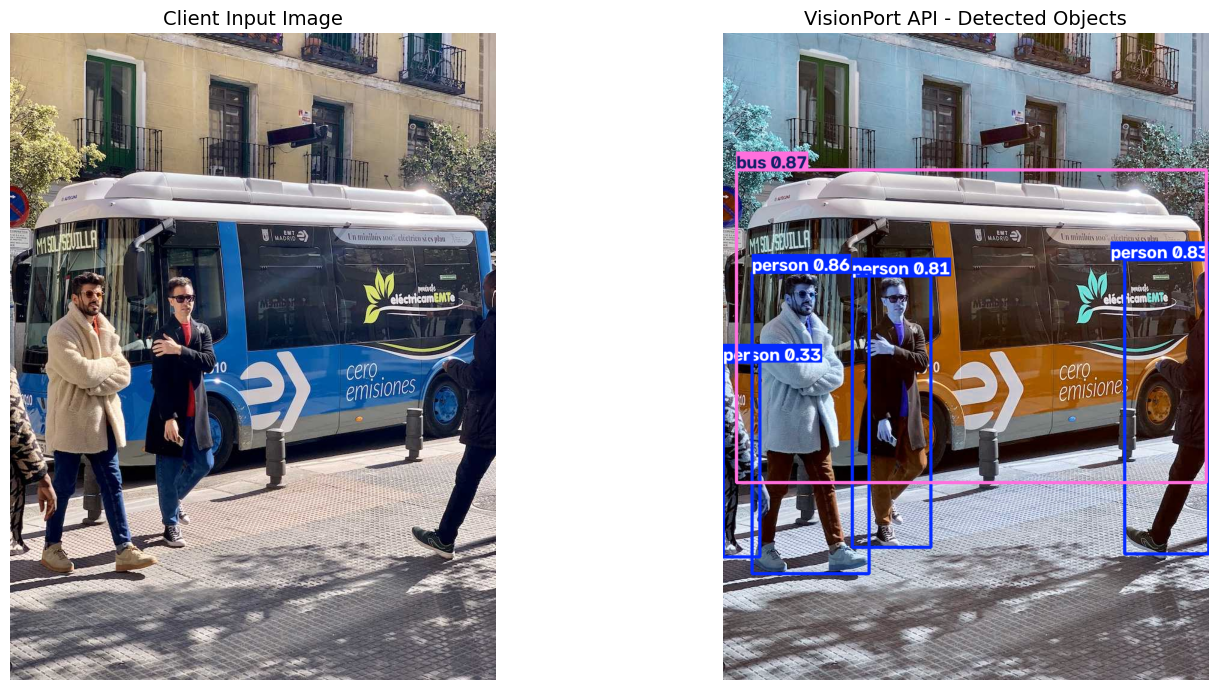

In [11]:
# CELL 10: GRAPHICAL OUTPUT - IMAGE DETECTION
plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Client Input Image", fontsize=14)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(detected_image)
plt.title("VisionPort API - Detected Objects", fontsize=14)
plt.axis("off")

plt.tight_layout()
plt.show()

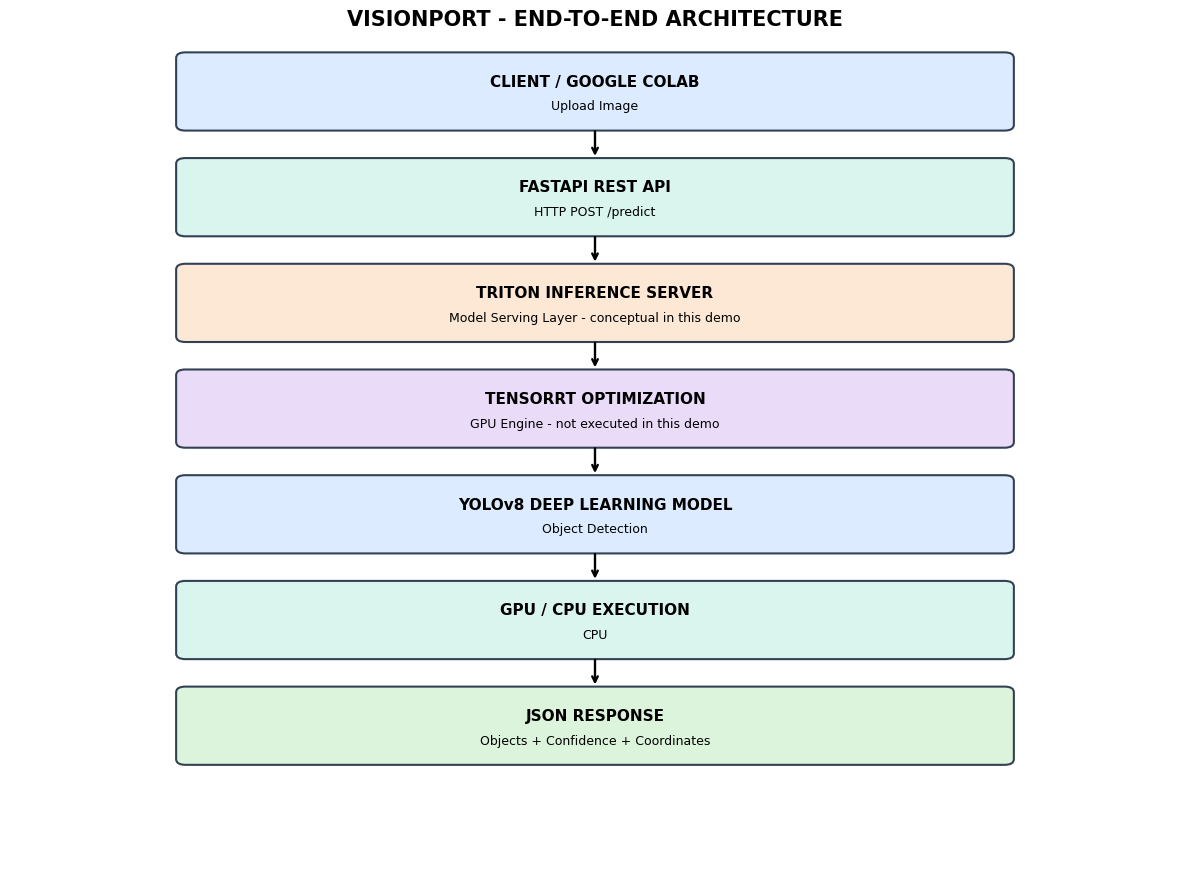

In [12]:
# CELL 11: GRAPHICAL OUTPUT - ARCHITECTURE DIAGRAM
fig, ax = plt.subplots(figsize=(12, 9))
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis("off")

architecture = [
    ("CLIENT / GOOGLE COLAB", "Upload Image"),
    ("FASTAPI REST API", "HTTP POST /predict"),
    ("TRITON INFERENCE SERVER", "Model Serving Layer - conceptual in this demo"),
    ("TENSORRT OPTIMIZATION", "GPU Engine - not executed in this demo"),
    ("YOLOv8 DEEP LEARNING MODEL", "Object Detection"),
    ("GPU / CPU EXECUTION", hardware),
    ("JSON RESPONSE", "Objects + Confidence + Coordinates"),
]

colors = ["#DCEBFF", "#D9F5EE", "#FCE8D5", "#EADCF8", "#DCEBFF", "#D9F5EE", "#DDF4DC"]

for i, (title, subtitle) in enumerate(architecture):
    y = 10.7 - i * 1.5

    rect = patches.FancyBboxPatch(
        (1.5, y), 7, 0.95,
        boxstyle="round,pad=0.08",
        facecolor=colors[i], edgecolor="#334155", linewidth=1.5
    )
    ax.add_patch(rect)

    ax.text(5, y + 0.62, title, ha="center", va="center", fontsize=11, fontweight="bold")
    ax.text(5, y + 0.27, subtitle, ha="center", va="center", fontsize=9)

    if i < len(architecture) - 1:
        ax.annotate(
            "", xy=(5, y - 0.48), xytext=(5, y - 0.05),
            arrowprops=dict(arrowstyle="->", lw=1.7)
        )

plt.title("VISIONPORT - END-TO-END ARCHITECTURE", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

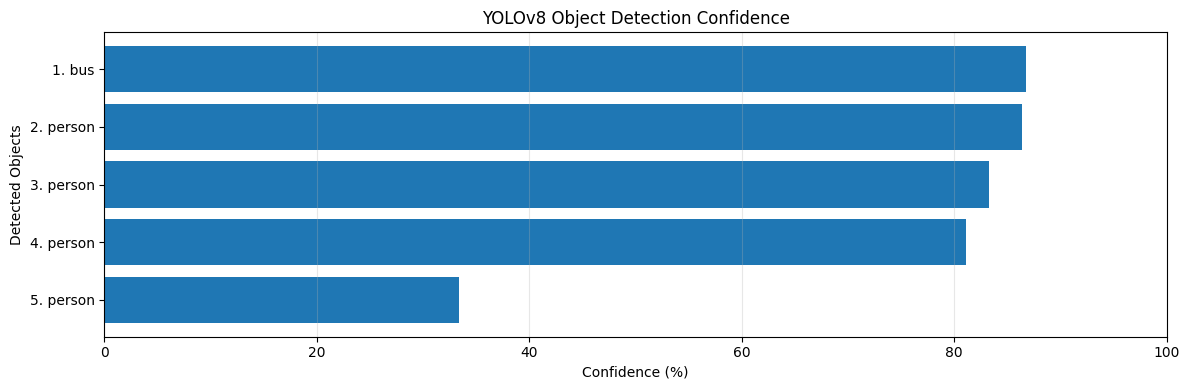

In [13]:
# CELL 12: GRAPHICAL OUTPUT - OBJECT CONFIDENCE
detections = output_data["detections"]

if detections:
    labels = [f"{i+1}. {d['object']}" for i, d in enumerate(detections)]
    confidence = [d["confidence"] for d in detections]

    plt.figure(figsize=(12, max(4, 0.4 * len(detections))))
    plt.barh(labels[::-1], confidence[::-1])
    plt.xlabel("Confidence (%)")
    plt.ylabel("Detected Objects")
    plt.title("YOLOv8 Object Detection Confidence")
    plt.xlim(0, 100)
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No objects detected - skipping confidence chart.")

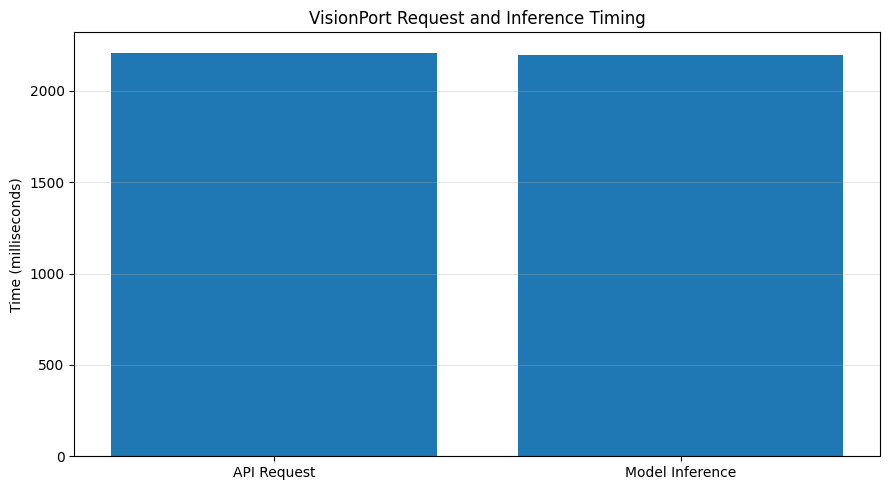

In [14]:
# CELL 13: GRAPHICAL OUTPUT - SYSTEM METRICS
metrics = {
    "API Request": api_elapsed * 1000,
    "Model Inference": output_data["inference_time_ms"],
}

plt.figure(figsize=(9, 5))
plt.bar(list(metrics.keys()), list(metrics.values()))
plt.ylabel("Time (milliseconds)")
plt.title("VisionPort Request and Inference Timing")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# CELL 14: FINAL SYSTEM REPORT
print("=" * 65)
print("             VISIONPORT FINAL SYSTEM REPORT")
print("=" * 65)
print("Image Acquisition        : SUCCESS")
print("FastAPI Server           : RUNNING")
print("HTTP POST Request        : SUCCESS")
print("YOLOv8 Model             : LOADED")
print("Object Detection         : COMPLETED")
print("Bounding Boxes           : GENERATED")
print("JSON Response            : RECEIVED")
print("GPU Available            :", gpu_available)
print("TensorRT Available       :", tensorrt_available)
print("Triton Client Available  :", triton_client_available)
print("Triton Server Running    :", triton_running)
print("Total Objects Detected   :", len(detections))
print("Inference Time           :", output_data["inference_time_ms"], "ms")
print("=" * 65)
print("VISIONPORT END-TO-END PIPELINE COMPLETED!")

             VISIONPORT FINAL SYSTEM REPORT
Image Acquisition        : SUCCESS
FastAPI Server           : RUNNING
HTTP POST Request        : SUCCESS
YOLOv8 Model             : LOADED
Object Detection         : COMPLETED
Bounding Boxes           : GENERATED
JSON Response            : RECEIVED
GPU Available            : False
TensorRT Available       : False
Triton Client Available  : False
Triton Server Running    : False
Total Objects Detected   : 5
Inference Time           : 2197.02 ms
VISIONPORT END-TO-END PIPELINE COMPLETED!
